# P1 — Robustness ranking re-analysis
Session 1 — 19.11.2026 — data download, loading, sanity check

In [ ]:
!curl -sI http://data.robustness.vision/ | head -3

HTTP/1.1 302 Found
Content-Type: text/html
Connection: keep-alive


In [ ]:
!curl -s http://data.robustness.vision/ | grep -o 'href="[^"]*"' | head -30

In [ ]:
!curl -sIL http://data.robustness.vision/ | grep -i -E "^HTTP|^location"

HTTP/1.1 302 Found
Location: https://nextcloud.mpi-klsb.mpg.de/index.php/s/bBnaTnTZWtZqMnE
HTTP/1.1 200 OK


In [ ]:
SHARE = "bBnaTnTZWtZqMnE"
BASE = "https://nextcloud.mpi-klsb.mpg.de/public.php/webdav"
!curl -s -X PROPFIND -u "{SHARE}:" -H "Depth: 1" {BASE}/ | grep -o -E "<d:href>[^<]*</d:href>|<d:getcontentlength>[^<]*</d:getcontentlength>"

<d:href>/public.php/webdav/</d:href>
<d:href>/public.php/webdav/cifar10.zip</d:href>
<d:getcontentlength>249653018</d:getcontentlength>
<d:href>/public.php/webdav/cifar100-accuracies.zip</d:href>
<d:getcontentlength>1145982</d:getcontentlength>
<d:href>/public.php/webdav/cifar100-adversarial-cm.zip</d:href>
<d:getcontentlength>551596222</d:getcontentlength>
<d:href>/public.php/webdav/cifar100-adversarial-confidence.zip</d:href>
<d:getcontentlength>2337191616</d:getcontentlength>
<d:href>/public.php/webdav/cifar100-clean-cm.zip</d:href>
<d:getcontentlength>13354982</d:getcontentlength>
<d:href>/public.php/webdav/cifar100-clean-confidence.zip</d:href>
<d:getcontentlength>70384197</d:getcontentlength>
<d:href>/public.php/webdav/cifar100-corruption-cm.zip</d:href>
<d:getcontentlength>1172328792</d:getcontentlength>
<d:href>/public.php/webdav/cifar100-corruption-confidence.zip</d:href>
<d:getcontentlength>5958037001</d:getcontentlength>
<d:href>/public.php/webdav/imagenet-accuracies.zip</d:

In [ ]:
!mkdir -p robustness-data
!curl -s -f -u "{SHARE}:" -o robustness-data/meta.zip {BASE}/meta.zip
!curl -s -f -u "{SHARE}:" -o robustness-data/cifar10.zip {BASE}/cifar10.zip
!ls -lh robustness-data


total 239M
-rw-r--r-- 1 root root 239M Nov 19 10:01 cifar10.zip
-rw-r--r-- 1 root root 139K Nov 19 10:00 meta.zip


In [ ]:
!unzip -l robustness-data/cifar10.zip | head -15
!unzip -l robustness-data/cifar10.zip | grep -c "_accuracy.json"

Archive:  robustness-data/cifar10.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
        0  2023-01-23 19:30   robustness-data/
        0  2023-01-23 19:30   robustness-data/cifar10/
   297490  2023-01-23 17:27   robustness-data/cifar10/aa_apgd-ce@Linf_accuracy.json
 15042106  2023-01-23 17:32   robustness-data/cifar10/aa_apgd-ce@Linf_cm.json
 55130091  2023-01-23 17:31   robustness-data/cifar10/aa_apgd-ce@Linf_confidence.json
   325269  2023-01-23 17:34   robustness-data/cifar10/aa_square@Linf_accuracy.json
 14686841  2023-01-23 17:38   robustness-data/cifar10/aa_square@Linf_cm.json
 56070419  2023-01-23 17:37   robustness-data/cifar10/aa_square@Linf_confidence.json
   249557  2023-01-23 17:53   robustness-data/cifar10/brightness_accuracy.json
  9347188  2023-01-23 17:57   robustness-data/cifar10/brightness_cm.json
 39589121  2023-01-23 17:55   robustness-data/cifar10/brightness_confidence.json
    84498  2023-01-23 17:25   robustness-data/cifar10/clean_accu

In [ ]:
!cd robustness-data && unzip -q -o meta.zip && unzip -q -o cifar10.zip "*_accuracy.json"
!find robustness-data -maxdepth 2 | head -30

robustness-data
robustness-data/robustness-data
robustness-data/robustness-data/cifar10
robustness-data/meta.zip
robustness-data/data
robustness-data/data/meta.json
robustness-data/cifar10.zip


In [ ]:
!mv robustness-data/robustness-data/cifar10 robustness-data/cifar10
!mv robustness-data/data/meta.json robustness-data/meta.json
!rmdir robustness-data/robustness-data robustness-data/data
!find robustness-data -maxdepth 1 | sort
!ls robustness-data/cifar10 | wc -l

robustness-data
robustness-data/cifar10
robustness-data/cifar10.zip
robustness-data/meta.json
robustness-data/meta.zip
20


In [ ]:
!git clone -q https://github.com/steffen-jung/robustness-dataset
import sys
sys.path.append("robustness-dataset")
from robustness_dataset import RobustnessDataset

data = RobustnessDataset(path="robustness-data")
print(len(data.non_isomorph_ids))
print(data.meta["epsilons"])

6466
{'aa_apgd-ce@Linf': [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 8.0], 'aa_square@Linf': [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 8.0], 'fgsm@Linf': [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 255.0], 'pgd@Linf': [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 8.0]}


In [ ]:
KEYS = ["clean", "fgsm@Linf", "pgd@Linf", "aa_apgd-ce@Linf", "aa_square@Linf"]
res = data.query(data="cifar10", key=KEYS, measure="accuracy")
r = res["cifar10"]

uid = data.get_uid(13433)
print(r["clean"]["accuracy"][uid])
print(r["pgd@Linf"]["accuracy"][uid][data.meta["epsilons"]["pgd@Linf"].index(1.0)])

0.893
0.336


In [ ]:
import pandas as pd

def acc(attack, eps):
    i = data.meta["epsilons"][attack].index(eps)
    return {a: v[i] for a, v in r[attack]["accuracy"].items()}

df = pd.DataFrame({
    "clean":    pd.Series(r["clean"]["accuracy"]),
    "fgsm_0.5": pd.Series(acc("fgsm@Linf", 0.5)),
    "fgsm_1":   pd.Series(acc("fgsm@Linf", 1.0)),
    "apgd_1":   pd.Series(acc("aa_apgd-ce@Linf", 1.0)),
    "square_1": pd.Series(acc("aa_square@Linf", 1.0)),
    "apgd_4":   pd.Series(acc("aa_apgd-ce@Linf", 4.0)),
    "square_4": pd.Series(acc("aa_square@Linf", 4.0)),
}).loc[data.non_isomorph_ids]

print(df.shape)
print(df.isna().sum().sum())
df.describe().round(3)

(6466, 7)
0


,clean,fgsm_0.5,fgsm_1,apgd_1,square_1,apgd_4,square_4
count,6466.000,6466.000,6466.000,6466.000,6466.000,6466.000,6466.000
mean,0.898,0.654,0.494,0.185,0.626,0.001,0.073
std,0.058,0.062,0.099,0.087,0.050,0.008,0.030
min,0.100,0.100,0.100,0.029,0.100,0.000,0.005
25%,0.892,0.628,0.439,0.132,0.606,0.000,0.053
50%,0.914,0.665,0.507,0.167,0.635,0.000,0.072
75%,0.926,0.696,0.565,0.210,0.659,0.000,0.092
max,0.946,0.773,0.692,0.540,0.736,0.106,0.252


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/P1 && cp -r robustness-data /content/drive/MyDrive/P1/

Mounted at /content/drive


In [ ]:
!ls -lh /content/drive/MyDrive/P1/robustness-data
!ls /content/drive/MyDrive/P1/robustness-data/cifar10 | wc -l

total 241M
drwx------ 2 root root 4.0K Nov 19 10:21 cifar10
-rw------- 1 root root 239M Nov 19 10:21 cifar10.zip
-rw------- 1 root root 2.1M Nov 19 10:21 meta.json
-rw------- 1 root root 139K Nov 19 10:21 meta.zip
20


In [ ]:
print((df["clean"] < 0.20).sum())
print(df.loc[df["clean"] < 0.20, "clean"].round(3).value_counts().head(10))

5
clean
0.1    5
Name: count, dtype: int64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!test -d robustness-data || cp -r /content/drive/MyDrive/P1/robustness-data .
!test -d robustness-dataset || git clone -q https://github.com/steffen-jung/robustness-dataset
import sys
sys.path.append("robustness-dataset")
from robustness_dataset import RobustnessDataset
import pandas as pd

DATASET = "cifar10"          # A6: "cifar100", then "ImageNet16-120"
data = RobustnessDataset(path="robustness-data")
KEYS = ["clean", "fgsm@Linf", "pgd@Linf", "aa_apgd-ce@Linf", "aa_square@Linf"]
r = data.query(data=DATASET, key=KEYS, measure="accuracy")[DATASET]

def acc(attack, eps):
    i = data.meta["epsilons"][attack].index(eps)
    return {a: v[i] for a, v in r[attack]["accuracy"].items()}

df = pd.DataFrame({
    "clean":    pd.Series(r["clean"]["accuracy"]),
    "fgsm_0.5": pd.Series(acc("fgsm@Linf", 0.5)),
    "fgsm_1":   pd.Series(acc("fgsm@Linf", 1.0)),
    "pgd_1":    pd.Series(acc("pgd@Linf", 1.0)),
    "apgd_1":   pd.Series(acc("aa_apgd-ce@Linf", 1.0)),
    "square_1": pd.Series(acc("aa_square@Linf", 1.0)),
    "apgd_4":   pd.Series(acc("aa_apgd-ce@Linf", 4.0)),
    "square_4": pd.Series(acc("aa_square@Linf", 4.0)),
}).loc[data.non_isomorph_ids]
print(df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(6466, 8)


In [ ]:
print(df["clean"].nlargest(5))
best_clean = df["clean"].idxmax()
print("best clean:", best_clean, data.meta["ids"][best_clean]["nb201-string"], repr(r["clean"]["accuracy"][best_clean]))
uid = data.get_uid(13433)
print("13433:", data.meta["ids"][uid]["nb201-string"])

13714    0.946
3731     0.945
10000    0.944
1425     0.943
1459     0.943
Name: clean, dtype: float64
best clean: 13714 |nor_conv_3x3~0|+|nor_conv_3x3~0|nor_conv_3x3~1|+|skip_connect~0|nor_conv_1x1~1|nor_conv_3x3~2| 0.946
13433: |avg_pool_3x3~0|+|nor_conv_1x1~0|skip_connect~1|+|nor_conv_1x1~0|nor_conv_1x1~1|skip_connect~2|


In [ ]:
CHEAP = ["clean", "fgsm_0.5", "fgsm_1", "pgd_1"]
rows = []
for t in ["apgd_1", "square_1"]:
    T = df[t] * 100
    opt = T.max()
    for c in CHEAP:
        best = df[c] == df[c].max()
        Tj = T[best].mean()
        rows.append({"target": t, "cheap": c, "tied_at_max": int(best.sum()),
                     "optimum_%": round(opt, 2), "T_j_%": round(Tj, 2), "proxy_gap_pp": round(opt - Tj, 2)})
q0 = pd.DataFrame(rows)
q0

,target,cheap,tied_at_max,optimum_%,T_j_%,proxy_gap_pp
0,apgd_1,clean,1,54.0,21.3,32.7
1,apgd_1,fgsm_0.5,1,54.0,21.6,32.4
2,apgd_1,fgsm_1,1,54.0,21.6,32.4
3,apgd_1,pgd_1,1,54.0,53.8,0.2
4,square_1,clean,1,73.6,71.1,2.5
5,square_1,fgsm_0.5,1,73.6,70.4,3.2
6,square_1,fgsm_1,1,73.6,70.4,3.2
7,square_1,pgd_1,1,73.6,65.2,8.4


In [ ]:
TABLE1 = {
    "apgd_1":   {"clean":  {"BANANAS": 18.62, "Local Search": 18.74, "Random Search": 17.84, "Regularized Evolution": 18.11},
                 "fgsm_1": {"BANANAS": 20.72, "Local Search": 23.18, "Random Search": 20.93, "Regularized Evolution": 22.59}},
    "square_1": {"clean":  {"BANANAS": 68.69, "Local Search": 69.59, "Random Search": 68.40, "Regularized Evolution": 68.92},
                 "fgsm_1": {"BANANAS": 68.01, "Local Search": 69.47, "Random Search": 68.44, "Regularized Evolution": 69.20}},
}
for t, by_cheap in TABLE1.items():
    opt = df[t].max() * 100
    for c, methods in by_cheap.items():
        Tj = q0.loc[(q0.target == t) & (q0.cheap == c), "T_j_%"].item()
        for m, v in methods.items():
            print(f"{t:9s} {c:7s} {m:22s} total {opt - v:6.2f} = proxy {opt - Tj:6.2f} + search {Tj - v:6.2f}")

apgd_1    clean   BANANAS                total  35.38 = proxy  32.70 + search   2.68
apgd_1    clean   Local Search           total  35.26 = proxy  32.70 + search   2.56
apgd_1    clean   Random Search          total  36.16 = proxy  32.70 + search   3.46
apgd_1    clean   Regularized Evolution  total  35.89 = proxy  32.70 + search   3.19
apgd_1    fgsm_1  BANANAS                total  33.28 = proxy  32.40 + search   0.88
apgd_1    fgsm_1  Local Search           total  30.82 = proxy  32.40 + search  -1.58
apgd_1    fgsm_1  Random Search          total  33.07 = proxy  32.40 + search   0.67
apgd_1    fgsm_1  Regularized Evolution  total  31.41 = proxy  32.40 + search  -0.99
square_1  clean   BANANAS                total   4.91 = proxy   2.50 + search   2.41
square_1  clean   Local Search           total   4.01 = proxy   2.50 + search   1.51
square_1  clean   Random Search          total   5.20 = proxy   2.50 + search   2.70
square_1  clean   Regularized Evolution  total   4.68 = proxy   2

In [ ]:
for t in ["apgd_1", "square_1"]:
    for c in ["clean", "fgsm_1"]:
        rank_c = df[c].rank(ascending=False, method="min")
        rank_t = df[t].rank(ascending=False, method="min")
        best_c, best_t = df[c].idxmax(), df[t].idxmax()
        print(f"{t} vs {c}: best by {c} = #{best_c} (rank under {t}: {int(rank_t[best_c])}); "
              f"best by {t} = #{best_t} (rank under {c}: {int(rank_c[best_t])})")

apgd_1 vs clean: best by clean = #13714 (rank under apgd_1: 1512); best by apgd_1 = #11933 (rank under clean: 6132)
apgd_1 vs fgsm_1: best by fgsm_1 = #655 (rank under apgd_1: 1448); best by apgd_1 = #11933 (rank under fgsm_1: 1347)
square_1 vs clean: best by clean = #13714 (rank under square_1: 13); best by square_1 = #12029 (rank under clean: 763)
square_1 vs fgsm_1: best by fgsm_1 = #655 (rank under square_1: 31); best by square_1 = #12029 (rank under fgsm_1: 343)


In [ ]:
# Check 1: exact clean accuracy from the confusion matrices
!unzip -q -o -j robustness-data/cifar10.zip "*/clean_cm.json" -d robustness-data/cifar10
import numpy as np
cm = data.query(data="cifar10", key="clean", measure="cm")["cifar10"]["clean"]["cm"]
m = np.array(cm[best_clean])
print("shape:", m.shape, "| images:", m.sum())
assert m.shape == (10, 10), "stop here and send me this output"
exact = pd.Series({a: np.trace(np.array(v)) / np.sum(v) for a, v in cm.items()}).loc[data.non_isomorph_ids]
print("best clean exact:", exact[best_clean], "| stored:", df.loc[best_clean, "clean"])
print("stored = rounded  :", np.isclose(df["clean"], exact.round(3)).mean())
print("stored = truncated:", np.isclose(df["clean"], np.floor(exact * 1000 + 1e-9) / 1000).mean())

shape: (10, 10) | images: 10000
best clean exact: 0.9456 | stored: 0.946
stored = rounded  : 0.9760284565419115
stored = truncated: 0.539901020723786


In [ ]:
# Check 2: identities and ranks for all four cheap evaluations
for t in ["apgd_1", "square_1"]:
    rank_t = df[t].rank(ascending=False, method="min")
    best_t = df[t].idxmax()
    print(f"{t}: best = #{best_t}, tied at max = {int((df[t] == df[t].max()).sum())}")
    for c in CHEAP:
        rank_c = df[c].rank(ascending=False, method="min")
        best_c = df[c].idxmax()
        print(f"   {c:8s} best = #{best_c:>5s} | its rank under {t}: {int(rank_t[best_c]):4d} | rank of #{best_t} under {c}: {int(rank_c[best_t])}")

apgd_1: best = #11933, tied at max = 1
   clean    best = #13714 | its rank under apgd_1: 1512 | rank of #11933 under clean: 6132
   fgsm_0.5 best = #  655 | its rank under apgd_1: 1448 | rank of #11933 under fgsm_0.5: 1471
   fgsm_1   best = #  655 | its rank under apgd_1: 1448 | rank of #11933 under fgsm_1: 1347
   pgd_1    best = # 8865 | its rank under apgd_1:    2 | rank of #11933 under pgd_1: 4
square_1: best = #12029, tied at max = 1
   clean    best = #13714 | its rank under square_1:   13 | rank of #12029 under clean: 763
   fgsm_0.5 best = #  655 | its rank under square_1:   31 | rank of #12029 under fgsm_0.5: 6
   fgsm_1   best = #  655 | its rank under square_1:   31 | rank of #12029 under fgsm_1: 343
   pgd_1    best = # 8865 | its rank under square_1: 2075 | rank of #12029 under pgd_1: 147


In [ ]:
# Check 3: a closer look at five architectures
picks = {"best clean": df["clean"].idxmax(), "best fgsm_1": df["fgsm_1"].idxmax(), "best pgd_1": df["pgd_1"].idxmax(),
         "best apgd_1": df["apgd_1"].idxmax(), "best square_1": df["square_1"].idxmax()}
for name, a in picks.items():
    print(f"{name:13s} #{a}: {df.loc[a, ['clean', 'fgsm_1', 'pgd_1', 'apgd_1', 'square_1']].round(3).to_dict()}")
    print("              ", data.id_to_string(a))

best clean    #13714: {'clean': 0.946, 'fgsm_1': 0.65, 'pgd_1': 0.438, 'apgd_1': 0.213, 'square_1': 0.711}
               |nor_conv_3x3~0|+|nor_conv_3x3~0|nor_conv_3x3~1|+|skip_connect~0|nor_conv_1x1~1|nor_conv_3x3~2|
best fgsm_1   #655: {'clean': 0.941, 'fgsm_1': 0.692, 'pgd_1': 0.461, 'apgd_1': 0.216, 'square_1': 0.704}
               |nor_conv_3x3~0|+|nor_conv_3x3~0|nor_conv_3x3~1|+|skip_connect~0|none~1|nor_conv_3x3~2|
best pgd_1    #8865: {'clean': 0.825, 'fgsm_1': 0.583, 'pgd_1': 0.588, 'apgd_1': 0.538, 'square_1': 0.652}
               |avg_pool_3x3~0|+|none~0|skip_connect~1|+|none~0|nor_conv_1x1~1|skip_connect~2|
best apgd_1   #11933: {'clean': 0.812, 'fgsm_1': 0.576, 'pgd_1': 0.584, 'apgd_1': 0.54, 'square_1': 0.649}
               |avg_pool_3x3~0|+|none~0|avg_pool_3x3~1|+|none~0|nor_conv_1x1~1|avg_pool_3x3~2|
best square_1 #12029: {'clean': 0.931, 'fgsm_1': 0.631, 'pgd_1': 0.495, 'apgd_1': 0.315, 'square_1': 0.736}
               |nor_conv_3x3~0|+|nor_conv_3x3~0|nor_conv_3x3~

In [ ]:
# Cell 9: highest exact clean accuracy, and what the rounding mismatches are
print("max exact clean:", exact.max(), "| arch:", exact.idxmax())
mism = exact.index[~np.isclose(df["clean"], exact.round(3))]
print("mismatches:", len(mism), "| 4th decimal of exact:", ((exact[mism] * 10000).round() % 10).value_counts().to_dict())

max exact clean: 0.9456 | arch: 13714
mismatches: 155 | 4th decimal of exact: {5.0: 155}


In [ ]:
# A4 — Cell 10: settings and helper functions
import numpy as np
from scipy.stats import kendalltau, spearmanr

N_CLASSES = 10                                   # CIFAR-10 (A6: 100, then 120)
CHEAP   = ["clean", "fgsm_0.5", "fgsm_1", "pgd_1"]
TARGETS = ["apgd_1", "square_1", "apgd_4", "square_4"]
FRACS   = [0.01, 0.05, 0.10]
OUT     = "/content/drive/MyDrive/P1/"           # results are saved here
TAG     = DATASET                                # used in file names

A = df[df["clean"] >= 2 / N_CLASSES]             # analysis set (plan §3)
print("analysis set:", len(A), "| excluded:", len(df) - len(A))

def topk_weights(x, k):
    kth = np.sort(x)[::-1][k - 1]
    above, tied = x > kth, x == kth
    w = above.astype(float)
    w[tied] = (k - above.sum()) / tied.sum()
    return w

def pair_metrics(c, t, clean):
    out = {"tau": kendalltau(c, t).statistic, "rho": spearmanr(c, t).statistic}
    for f in FRACS:
        k = max(1, round(f * len(c)))
        wc, wt = topk_weights(c, k), topk_weights(t, k)
        out[f"ov{round(f * 100)}"] = wc @ wt / k
        if f == 0.05:
            out["top5_T_byC"] = 100 * (wc @ t) / k
            out["top5_T_byT"] = 100 * (wt @ t) / k
            out["top5_clean_byC"] = 100 * (wc @ clean) / k
    return out

analysis set: 6461 | excluded: 5


In [ ]:
# A4 — Cell 11: point estimates for the 16 pairs
clean = A["clean"].to_numpy()
rows = []
for t in TARGETS:
    T = A[t].to_numpy()
    for c in CHEAP:
        C = A[c].to_numpy()
        m = pair_metrics(C, T, clean)
        m["regret_pp"] = 100 * (T.max() - T[C == C.max()].mean())
        for f in FRACS:
            k = max(1, round(f * len(C)))
            m[f"tiedC_{round(f * 100)}"] = int((C == np.sort(C)[::-1][k - 1]).sum())
            m[f"tiedT_{round(f * 100)}"] = int((T == np.sort(T)[::-1][k - 1]).sum())
        rows.append({"target": t, "cheap": c, **m})
point = pd.DataFrame(rows).set_index(["target", "cheap"])
assert (point["top5_T_byT"] >= point["top5_T_byC"] - 1e-9).all()
point.to_csv(f"{OUT}a4_point_{TAG}.csv")
print(point.round(3).to_string())

                     tau    rho    ov1    ov5  top5_T_byC  top5_T_byT  top5_clean_byC   ov10  regret_pp  tiedC_1  tiedT_1  tiedC_5  tiedT_5  tiedC_10  tiedT_10
target   cheap                                                                                                                                                 
apgd_1   clean    -0.106 -0.195  0.000  0.000      17.407      43.921          93.768  0.000       32.7       35        2       96        8       139         5
         fgsm_0.5  0.262  0.350  0.000  0.003      20.531      43.921          93.501  0.020       32.4       10        2       29        8        40         5
         fgsm_1    0.214  0.279  0.000  0.000      20.139      43.921          93.418  0.006       32.4        6        2       17        8        19         5
         pgd_1     0.699  0.866  0.938  0.746      41.756      43.921          83.646  0.692        0.2        3        2        7        8        17         5
square_1 clean     0.450  0.600  0.108  

In [ ]:
# A4 — Cell 12: paired bootstrap (B = 1000, seed 0)
rng = np.random.default_rng(0)
n, B = len(A), 1000
X = {col: A[col].to_numpy() for col in CHEAP + TARGETS}
boot = []
for b in range(B):
    i = rng.integers(0, n, n)                    # the same rows for every pair = paired
    for t in TARGETS:
        for c in CHEAP:
            boot.append({"b": b, "target": t, "cheap": c, **pair_metrics(X[c][i], X[t][i], X["clean"][i])})
    if b % 100 == 0:
        print(b, end=" ")
boot = pd.DataFrame(boot)
boot.to_csv(f"{OUT}a4_bootstrap_{TAG}.csv", index=False)
print("\n", boot.shape)

0 100 200 300 400 500 600 700 800 900 
 (16000, 11)


In [ ]:
# A4 — Cell 13: point estimate [95% percentile interval]
METRICS = ["tau", "rho", "ov1", "ov5", "ov10", "top5_T_byC", "top5_T_byT", "top5_clean_byC"]
g = boot.groupby(["target", "cheap"])[METRICS]
lo, hi = g.quantile(0.025), g.quantile(0.975)
summary = pd.DataFrame(index=point.index)
for m in METRICS:
    summary[m] = [f"{point.loc[ix, m]:.2f} [{lo.loc[ix, m]:.2f}, {hi.loc[ix, m]:.2f}]" for ix in point.index]
summary["regret_pp"] = point["regret_pp"].round(1)
summary.to_csv(f"{OUT}a4_summary_{TAG}.csv")
print(summary.to_string())

                                    tau                   rho                ov1                ov5               ov10            top5_T_byC            top5_T_byT        top5_clean_byC  regret_pp
target   cheap                                                                                                                                                                                     
apgd_1   clean     -0.11 [-0.13, -0.09]  -0.19 [-0.22, -0.17]  0.00 [0.00, 0.00]  0.00 [0.00, 0.00]  0.00 [0.00, 0.00]  17.41 [17.12, 17.69]  43.92 [43.11, 44.72]  93.77 [93.73, 93.80]       32.7
         fgsm_0.5     0.26 [0.25, 0.28]     0.35 [0.33, 0.38]  0.00 [0.00, 0.00]  0.00 [0.00, 0.01]  0.02 [0.01, 0.03]  20.53 [20.20, 20.90]  43.92 [43.11, 44.72]  93.50 [93.45, 93.55]       32.4
         fgsm_1       0.21 [0.20, 0.23]     0.28 [0.26, 0.30]  0.00 [0.00, 0.00]  0.00 [0.00, 0.00]  0.01 [0.00, 0.01]  20.14 [19.92, 20.40]  43.92 [43.11, 44.72]  93.42 [93.38, 93.45]       32.4
         pgd_1      

In [ ]:
# A5 — Cell 14: floor diagnostics (plan §6)
boot = pd.read_csv(f"{OUT}a4_bootstrap_{TAG}.csv")
rng = np.random.default_rng(0)
IDX = [rng.integers(0, len(A), len(A)) for _ in range(1000)]   # the same resamples as cell 12
fs = pd.Series({t: (A[t] < 0.01).mean() for t in TARGETS})      # floor share per target
rows = []
for t in TARGETS:
    T = A[t].to_numpy()
    for c in CHEAP:
        C = A[c].to_numpy()
        row = {"target": t, "cheap": c, "floor_share": fs[t], "zero_share": (T == 0).mean(), "n_above_1pct": int((T >= 0.01).sum())}
        if row["n_above_1pct"] >= 100:
            keep = T >= 0.01
            bs = [kendalltau(C[i][T[i] >= 0.01], T[i][T[i] >= 0.01]).statistic for i in IDX]
            row.update(cond_tau=kendalltau(C[keep], T[keep]).statistic, cond_lo=np.percentile(bs, 2.5), cond_hi=np.percentile(bs, 97.5))
        rows.append(row)
fl = pd.DataFrame(rows).set_index(["target", "cheap"])
print(fl.round(3).to_string())

                   floor_share  zero_share  n_above_1pct  cond_tau  cond_lo  cond_hi
target   cheap                                                                      
apgd_1   clean           0.000       0.000          6466    -0.106   -0.126   -0.087
         fgsm_0.5        0.000       0.000          6466     0.262    0.245    0.280
         fgsm_1          0.000       0.000          6466     0.214    0.197    0.230
         pgd_1           0.000       0.000          6466     0.699    0.690    0.709
square_1 clean           0.000       0.000          6466     0.450    0.436    0.464
         fgsm_0.5        0.000       0.000          6466     0.683    0.674    0.690
         fgsm_1          0.000       0.000          6466     0.571    0.561    0.581
         pgd_1           0.000       0.000          6466     0.556    0.541    0.571
apgd_4   clean           0.972       0.853           183    -0.643   -0.690   -0.591
         fgsm_0.5        0.972       0.853           183    -0.57

In [ ]:
# A5 — Cell 15: baselines (plan §8)
rng = np.random.default_rng(0)
clean = A["clean"].to_numpy()
rand = pd.DataFrame([{"target": t, **pair_metrics(rng.permutation(len(A)).astype(float), A[t].to_numpy(), clean)}
                     for _ in range(1000) for t in TARGETS]).groupby("target").mean()
print("Random ranking, mean of 1000 permutations:")
print(rand[["tau", "ov1", "ov5", "ov10", "top5_T_byC"]].round(3).to_string())
M = ["ov5", "tau", "top5_T_byC"]
base = boot[boot.cheap == "clean"].set_index(["b", "target"])[M]
for c in ["fgsm_0.5", "fgsm_1"]:
    d = boot[boot.cheap == c].set_index(["b", "target"])[M] - base           # same b = same resample
    est = point.xs(c, level="cheap")[M] - point.xs("clean", level="cheap")[M]
    lo, hi = d.groupby("target").quantile(0.025), d.groupby("target").quantile(0.975)
    print(f"\n{c} minus clean: difference [95% interval]")
    print((est.round(3).astype(str) + " [" + lo.round(3).astype(str) + ", " + hi.round(3).astype(str) + "]").to_string())

Random ranking, mean of 1000 permutations:
          tau    ov1   ov5   ov10  top5_T_byC
target                                       
apgd_1   -0.0  0.011  0.05  0.101      18.527
apgd_4   -0.0  0.010  0.05  0.100       0.127
square_1  0.0  0.010  0.05  0.100      62.576
square_4 -0.0  0.010  0.05  0.100       7.269

fgsm_0.5 minus clean: difference [95% interval]
                           ov5                   tau            top5_T_byC
target                                                                    
apgd_1      0.003 [0.0, 0.012]  0.369 [0.357, 0.381]  3.124 [2.738, 3.541]
apgd_4    0.013 [0.003, 0.026]  0.217 [0.201, 0.235]  0.023 [0.014, 0.035]
square_1  0.183 [0.144, 0.227]  0.232 [0.221, 0.244]  0.918 [0.761, 1.065]
square_4   0.08 [0.049, 0.111]  0.268 [0.256, 0.281]  1.462 [1.277, 1.658]

fgsm_1 minus clean: difference [95% interval]
                           ov5                   tau            top5_T_byC
target                                                      

In [ ]:
# A5 — Cell 16: verdicts (plan §7); F is decided first
q = boot.groupby(["target", "cheap"])[["ov5", "tau"]].quantile(0.025)
V = point[["tau", "ov5", "top5_T_byC", "top5_T_byT", "top5_clean_byC", "tiedC_5", "tiedT_5"]].join(fl.reindex(columns=["floor_share", "cond_tau", "cond_lo"]))
V["tau_lo"], V["ov5_lo"] = q["tau"], q["ov5"]
V["selection"] = np.select([V.ov5_lo >= 0.5, V.ov5_lo >= 0.25], ["PASS", "WARN"], "FAIL")
V["outcome"] = np.select([V.floor_share > 0.5, V.selection == "FAIL", V.tau_lo >= 0.5], ["F", "C", "A"], "B")
V["floor_effect"] = np.select([V.floor_share <= 0.5, V.cond_lo.isna(), V.cond_lo >= 0.5], ["", "not assessable", "supported"], "not supported")
V.loc[V.outcome == "F", "selection"] = "—"
V.to_csv(f"{OUT}a5_verdicts_{TAG}.csv")
print(V.round(3).to_string())

                     tau    ov5  top5_T_byC  top5_T_byT  top5_clean_byC  tiedC_5  tiedT_5  floor_share  cond_tau  cond_lo  tau_lo  ov5_lo selection outcome   floor_effect
target   cheap                                                                                                                                                            
apgd_1   clean    -0.106  0.000      17.407      43.921          93.768       96        8        0.000    -0.106   -0.126  -0.126   0.000      FAIL       C               
         fgsm_0.5  0.262  0.003      20.531      43.921          93.501       29        8        0.000     0.262    0.245   0.245   0.000      FAIL       C               
         fgsm_1    0.214  0.000      20.139      43.921          93.418       17        8        0.000     0.214    0.197   0.197   0.000      FAIL       C               
         pgd_1     0.699  0.746      41.756      43.921          83.646        7        8        0.000     0.699    0.690   0.690   0.716      PA

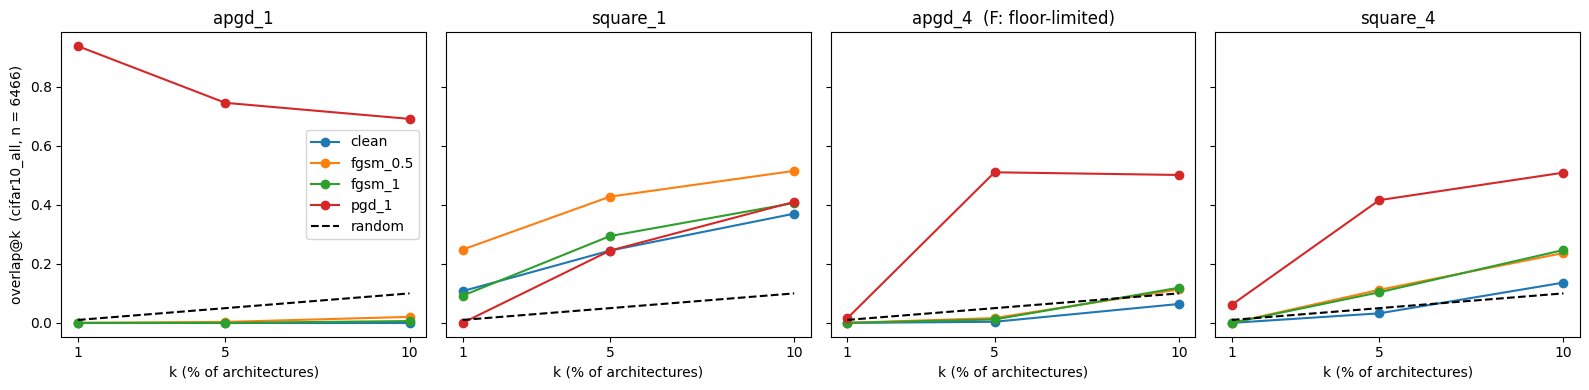

In [ ]:
# A5 — Cell 17: figure overlap@k against k (plan §11)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, t in zip(axes, TARGETS):
    for c in CHEAP:
        ax.plot([1, 5, 10], point.loc[(t, c), ["ov1", "ov5", "ov10"]].to_numpy(), marker="o", label=c)
    ax.plot([1, 5, 10], [0.01, 0.05, 0.10], "k--", label="random")
    ax.set_title(t + ("  (F: floor-limited)" if fs[t] > 0.5 else ""))
    ax.set_xticks([1, 5, 10])
    ax.set_xlabel("k (% of architectures)")
axes[0].set_ylabel(f"overlap@k  ({TAG}, n = {len(A)})")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{OUT}a5_overlap_at_k_{TAG}.png", dpi=150)
plt.show()

In [ ]:
# A5 — Cell 18: sensitivity analysis on all architectures (plan §3)
A, TAG = df, DATASET + "_all"
print("architectures:", len(A))

architectures: 6466


In [ ]:
# A5 — Cell 19 (EXPLORATORY, not in the plan): does 3-decimal rounding explain the Fig. 3 difference for APGD-CE eps = 4?
!unzip -q -o -j robustness-data/cifar10.zip "*/aa_apgd-ce@Linf_cm.json" -d robustness-data/cifar10
cm4 = data.query(data=DATASET, key="aa_apgd-ce@Linf", measure="cm")[DATASET]["aa_apgd-ce@Linf"]["cm"]
e = data.meta["epsilons"]["aa_apgd-ce@Linf"].index(4.0)
print("shape:", np.array(cm4[df.index[0]]).shape)
assert np.array(cm4[df.index[0]]).shape == (7, 10, 10), "stop here and send me this output"
ex4 = pd.Series({a: np.trace(np.array(v)[e]) / np.sum(np.array(v)[e]) for a, v in cm4.items()})
for name, S in [("analysis set", A), ("all architectures", df)]:
    x = ex4.loc[S.index]
    print(f"\n{name}: stored = rounded exact: {np.isclose(S['apgd_4'], x.round(3)).mean():.3f} | zero share stored {(S['apgd_4'] == 0).mean():.3f}, exact {(x == 0).mean():.3f}")
    for c in CHEAP:
        print(f"   {c:8s} tau stored {kendalltau(S[c], S['apgd_4']).statistic:6.3f} | tau exact {kendalltau(S[c], x).statistic:6.3f}")

shape: (7, 10, 10)

analysis set: stored = rounded exact: 0.999 | zero share stored 0.854, exact 0.564
   clean    tau stored -0.108 | tau exact  0.029
   fgsm_0.5 tau stored  0.110 | tau exact  0.270
   fgsm_1   tau stored  0.143 | tau exact  0.294
   pgd_1    tau stored  0.378 | tau exact  0.490

all architectures: stored = rounded exact: 0.999 | zero share stored 0.853, exact 0.564
   clean    tau stored -0.110 | tau exact  0.027
   fgsm_0.5 tau stored  0.107 | tau exact  0.268
   fgsm_1   tau stored  0.140 | tau exact  0.291
   pgd_1    tau stored  0.373 | tau exact  0.487
